# 05 · Ejercicios

**Objetivo de este cuaderno:** practicar lo de 01 a 04 sin rehacer toda la serie. Hay ejercicios ejecutables (celdas que deben correr de principio a fin) y preguntas de criterio, pensadas para un contexto de producción. Las **soluciones** están al final; conviene intentar cada ejercicio antes de bajar a ellas.

Si no has ejecutado 02 y 03, los ejercicios 1 y 4 siguen siendo factibles. El 2, el 3 y el 5 usan artefactos de esos cuadernos.


In [1]:
from pathlib import Path
import os, sys, json, time, gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    softmax_temperatura,
    divergencia_kl,
    perdida_destilacion,
    construir_mlp,
    construir_estudiante_sentimiento,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    guardar_checkpoint,
    cargar_checkpoint,
    evaluar_loader,
    medir_latencia_ms,
    entrenar_epoca,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42


## Ejercicio 1 · Softmax con temperatura, a mano

Implementa `mi_softmax(logits, T)` en NumPy, numéricamente estable, y comprueba que coincide con `softmax_temperatura` del módulo compartido en varios vectores y temperaturas. No uses `scipy` ni `torch.softmax` dentro de tu función.


In [2]:
def mi_softmax(logits, T=1.0):
    # TODO: reemplaza esta implementación si quieres escribirla tú.
    # La celda de comprobación de más abajo debe seguir pasando.
    logits = np.asarray(logits, dtype=np.float64)
    z = logits / float(T)
    z = z - np.max(z, axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


rng = np.random.default_rng(SEMILLA)
casos = [
    np.array([2.0, 1.0, 0.1]),
    np.array([50.0, 49.0, 10.0]),  # valores grandes: aquí falla una exp ingenua
    rng.normal(size=(4, 10)),
]
for z in casos:
    for T in (0.5, 1.0, 3.0, 8.0):
        np.testing.assert_allclose(
            mi_softmax(z, T), softmax_temperatura(z, temperature=T), rtol=1e-10, atol=1e-10
        )
print("Ejercicio 1: tu softmax coincide con el del módulo en todos los casos.")


Ejercicio 1: tu softmax coincide con el del módulo en todos los casos.


## Ejercicio 2 · Leer las blandas de un profesor real (MNIST)

Si existe `modelos/mnist_profesor.pt`, carga el profesor, toma 8 imágenes de test y pinta, para cada una, las probabilidades a \(T=1\) y a \(T=5\). Contesta (en una celda markdown tuya, o en voz alta): ¿en qué dígitos se ve más el conocimiento oscuro? ¿A qué clase «se parece» un 3 o un 4 según el profesor?


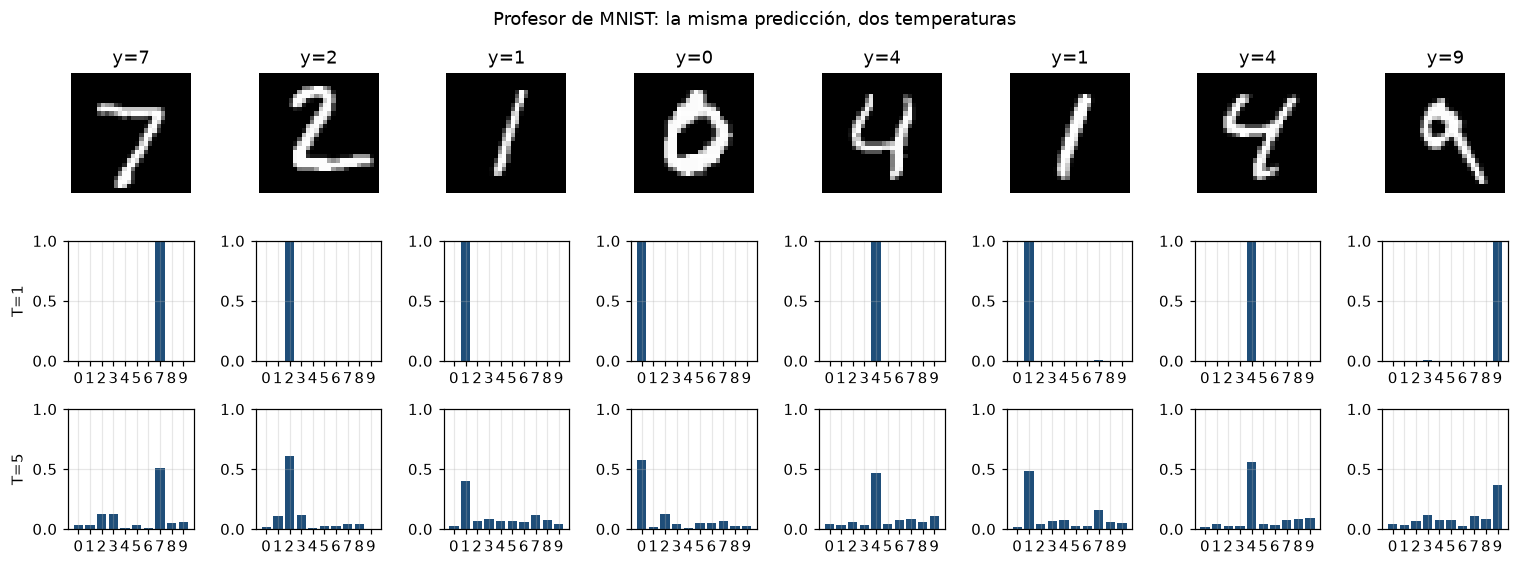

Predicción dura: [7 2 1 0 4 1 4 9] etiquetas: [7 2 1 0 4 1 4 9]


In [3]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

ruta_prof = RUTAS["modelos"] / "mnist_profesor.pt"
if not ruta_prof.exists():
    print("No está modelos/mnist_profesor.pt. Ejecuta el cuaderno 02 y vuelve a esta celda.")
else:
    meta_mnist = cargar_json(RUTAS["resultados"] / "mnist.json") if (RUTAS["resultados"] / "mnist.json").exists() else None
    anchos = (meta_mnist["modelos"]["profesor"]["anchos"] if meta_mnist else [784, 256, 128, 10])
    drop_p = (meta_mnist.get("dropout_profesor", 0.2) if meta_mnist else 0.2)
    profesor = construir_mlp(anchos, dropout=drop_p)
    cargar_checkpoint(profesor, ruta_prof, map_location="cpu")
    profesor.to(DEVICE).eval()

    tfm = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,)),
            transforms.Lambda(lambda t: t.reshape(-1)),
        ]
    )
    test = datasets.MNIST(RUTAS["datos"] / "mnist", train=False, download=False, transform=tfm)
    x, y = next(iter(DataLoader(test, batch_size=8, shuffle=False)))
    with torch.no_grad():
        logits = profesor(x.to(DEVICE)).cpu().numpy()

    fig, ejes = plt.subplots(3, 8, figsize=(14, 5.2))
    for i in range(8):
        img = x[i].reshape(28, 28) * 0.3081 + 0.1307
        ejes[0, i].imshow(img.numpy(), cmap="gray")
        ejes[0, i].set_title(f"y={int(y[i])}")
        ejes[0, i].axis("off")
        for fila, T, titulo in [(1, 1.0, "T=1"), (2, 5.0, "T=5")]:
            ejes[fila, i].bar(range(10), softmax_temperatura(logits[i], temperature=T), color="#1f4e79")
            ejes[fila, i].set_ylim(0, 1)
            ejes[fila, i].set_xticks(range(10))
            if i == 0:
                ejes[fila, i].set_ylabel(titulo)
    fig.suptitle("Profesor de MNIST: la misma predicción, dos temperaturas")
    fig.tight_layout()
    fig.savefig(RUTAS["resultados"] / "fig_ejercicio2_blandas_mnist.png", bbox_inches="tight")
    plt.show()
    print("Predicción dura:", logits.argmax(axis=1), "etiquetas:", y.numpy())


## Ejercicio 3 · Un profesor inútil

La destilación no es magia: copia al profesor, también cuando el profesor no merece ser copiado. En esta celda se entrena, sobre un subconjunto pequeño de MNIST y **una sola época**, un estudiante con:

- las blandas del profesor real (si está el checkpoint);
- unas «blandas» aleatorias (logits gaussianos, un profesor de ruido).

Compara las exactitudes en test. ¿Qué esperas antes de ejecutar? ¿Lo confirma el número?


In [4]:
import torch
from torch import optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

ruta_prof = RUTAS["modelos"] / "mnist_profesor.pt"
if not ruta_prof.exists():
    print("No está el profesor de MNIST. Ejecuta el cuaderno 02 y vuelve.")
else:
    meta = cargar_json(RUTAS["resultados"] / "mnist.json")
    anchos_p = meta["modelos"]["profesor"]["anchos"]
    anchos_e = meta["modelos"]["estudiante_duro"]["anchos"]
    drop_p = meta.get("dropout_profesor", 0.2)
    drop_e = meta.get("dropout_estudiante", 0.0)
    profesor = construir_mlp(anchos_p, dropout=drop_p)
    cargar_checkpoint(profesor, ruta_prof, map_location="cpu")
    profesor.to(DEVICE).eval()
    for p in profesor.parameters():
        p.requires_grad_(False)

    tfm = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,)),
            transforms.Lambda(lambda t: t.reshape(-1)),
        ]
    )
    train_full = datasets.MNIST(RUTAS["datos"] / "mnist", train=True, download=False, transform=tfm)
    test_full = datasets.MNIST(RUTAS["datos"] / "mnist", train=False, download=False, transform=tfm)
    g = torch.Generator().manual_seed(SEMILLA)
    idx = torch.randperm(len(train_full), generator=g).tolist()[:2000]
    loader_mini = DataLoader(Subset(train_full, idx), batch_size=128, shuffle=True)
    loader_test = DataLoader(Subset(test_full, list(range(2000))), batch_size=256, shuffle=False)

    class ProfesorRuido(torch.nn.Module):
        def forward(self, x):
            return torch.randn(x.size(0), 10, device=x.device)

    ruido = ProfesorRuido().to(DEVICE)

    fijar_semilla(SEMILLA)
    est_real = construir_mlp(anchos_e, dropout=drop_e).to(DEVICE)
    estado = {k: v.detach().cpu().clone() for k, v in est_real.state_dict().items()}
    est_ruido = construir_mlp(anchos_e, dropout=drop_e).to(DEVICE)
    est_ruido.load_state_dict(estado)

    opt1 = optim.Adam(est_real.parameters(), lr=1e-3)
    opt2 = optim.Adam(est_ruido.parameters(), lr=1e-3)
    entrenar_epoca(est_real, loader_mini, opt1, DEVICE, profesor=profesor, temperature=3.0, alpha=1.0)
    entrenar_epoca(est_ruido, loader_mini, opt2, DEVICE, profesor=ruido, temperature=3.0, alpha=1.0)

    acc_real = evaluar_loader(est_real, loader_test, DEVICE)["exactitud"]
    acc_ruido = evaluar_loader(est_ruido, loader_test, DEVICE)["exactitud"]
    print(f"destilado de un profesor real (1 época, alpha=1): {acc_real:.3f}")
    print(f"destilado de un profesor de ruido (1 época, alpha=1): {acc_ruido:.3f}")
    print("Un profesor inútil, con alpha=1, arrastra al estudiante. Las blandas no son un atajo si la fuente es mala.")


destilado de un profesor real (1 época, alpha=1): 0.425
destilado de un profesor de ruido (1 época, alpha=1): 0.113
Un profesor inútil, con alpha=1, arrastra al estudiante. Las blandas no son un atajo si la fuente es mala.


## Ejercicio 4 · Qué registrarías en un *run*

Construye un diccionario `registro_run` (el equivalente a parámetros + métricas de MLflow) para el experimento de sentimiento del cuaderno 03. Debe incluir, como mínimo: identidad del profesor, arquitectura del estudiante, \(T\), \(\alpha\), semilla, recuento de datos, exactitudes de los tres roles y una latencia. Si existe `resultados/sentimiento.json`, rellénalo con cifras reales. Si no, déjalo con el esquema y valores `None`.


In [5]:
ruta = RUTAS["resultados"] / "sentimiento.json"
datos = cargar_json(ruta) if ruta.exists() else None

registro_run = {
    "params": {
        "profesor_id": None,
        "estudiante_arquitectura": None,
        "temperature": None,
        "alpha": None,
        "semilla": None,
        "n_train": None,
        "n_test": None,
        "max_len": None,
        "dispositivo": None,
    },
    "metrics": {
        "acc_profesor": None,
        "acc_estudiante_duro": None,
        "acc_estudiante_destilado": None,
        "ms_por_ejemplo_profesor": None,
        "ms_por_ejemplo_estudiante_destilado": None,
        "params_profesor": None,
        "params_estudiante": None,
    },
}

if datos:
    registro_run["params"].update(
        {
            "profesor_id": datos["profesor"],
            "estudiante_arquitectura": "embedding-gru-bidireccional",
            "temperature": datos["temperature"],
            "alpha": datos["alpha"],
            "semilla": datos["semilla"],
            "n_train": datos["n_train"],
            "n_test": datos["n_test"],
            "max_len": datos["max_len"],
            "dispositivo": datos["dispositivo"],
        }
    )
    m = datos["modelos"]
    registro_run["metrics"].update(
        {
            "acc_profesor": m["profesor"]["exactitud"],
            "acc_estudiante_duro": m["estudiante_duro"]["exactitud"],
            "acc_estudiante_destilado": m["estudiante_destilado"]["exactitud"],
            "ms_por_ejemplo_profesor": m["profesor"]["latencia_ms_por_ejemplo_media"],
            "ms_por_ejemplo_estudiante_destilado": m["estudiante_destilado"]["latencia_ms_por_ejemplo_media"],
            "params_profesor": m["profesor"]["parametros"],
            "params_estudiante": m["estudiante_destilado"]["parametros"],
        }
    )

assert registro_run["params"].keys() >= {
    "profesor_id", "temperature", "alpha", "semilla", "n_train"
}
print(json.dumps(registro_run, ensure_ascii=False, indent=2))
guardar_json(registro_run, RUTAS["resultados"] / "ejercicio4_registro_run.json")


{
  "params": {
    "profesor_id": "distilbert-base-uncased-finetuned-sst-2-english",
    "estudiante_arquitectura": "embedding-gru-bidireccional",
    "temperature": 3.0,
    "alpha": 0.7,
    "semilla": 42,
    "n_train": 3000,
    "n_test": 872,
    "max_len": 64,
    "dispositivo": "cpu"
  },
  "metrics": {
    "acc_profesor": 0.9105504587155964,
    "acc_estudiante_duro": 0.6502293577981652,
    "acc_estudiante_destilado": 0.6743119266055045,
    "ms_por_ejemplo_profesor": 8.694339081330327,
    "ms_por_ejemplo_estudiante_destilado": 0.08040869922751881,
    "params_profesor": 66955010,
    "params_estudiante": 2003586
  }
}


PosixPath('/workspace/destilacion/resultados/ejercicio4_registro_run.json')

## Ejercicio 5 · Un criterio de promoción (pregunta de criterio)

Imagina un servicio de sentimiento con este acuerdo interno:

- la exactitud en el conjunto de evaluación no puede quedar a más de **4 puntos** del profesor;
- el p95 de latencia de un ejemplo en CPU tiene que ser **al menos 5 veces menor** que el del profesor, medido en la misma máquina.

Con las cifras de `resultados/sentimiento.json` (o de la comparativa del cuaderno 04), ¿promocionarías al estudiante destilado al camino de la petición? Escribe el cálculo y la decisión. Si el estudiante no cumple, ¿qué probarías antes de rendirte (más datos, otro \(T\), otra arquitectura, destilar un estudiante a medio camino entre los dos tamaños)?

No hay una única respuesta correcta: lo que se evalúa es que uses **los dos** criterios, no solo la exactitud.


In [6]:
ruta = RUTAS["resultados"] / "sentimiento.json"
if not ruta.exists():
    print("No está resultados/sentimiento.json. Ejecuta el cuaderno 03 (y, si puedes, el 04) y vuelve.")
else:
    d = cargar_json(ruta)["modelos"]
    acc_p = d["profesor"]["exactitud"]
    acc_k = d["estudiante_destilado"]["exactitud"]
    # En 03 medimos media, p50 y p95 por *lote*. Aproximamos el p95 por ejemplo
    # dividiendo el p95 del lote por el tamaño de lote (es una cota, no una medida por request).
    p95_p = d["profesor"]["latencia_ms_lote_p95"] / d["profesor"]["latencia_tamano_lote"]
    p95_k = d["estudiante_destilado"]["latencia_ms_lote_p95"] / d["estudiante_destilado"]["latencia_tamano_lote"]
    hueco_puntos = (acc_p - acc_k) * 100
    aceleracion = p95_p / p95_k if p95_k else float("inf")
    cumple_calidad = hueco_puntos <= 4.0 + 1e-9
    cumple_latencia = aceleracion >= 5.0
    decision = "PROMOCIONAR" if (cumple_calidad and cumple_latencia) else "NO PROMOCIONAR"
    print(f"hueco de exactitud: {hueco_puntos:.2f} puntos  (máx. admitido: 4)  → calidad ok={cumple_calidad}")
    print(f"aceleración p95 aprox.: {aceleracion:.1f}×  (mín. exigido: 5×)  → latencia ok={cumple_latencia}")
    print(f"decisión según el enunciado: {decision}")
    guardar_json(
        {
            "hueco_puntos": hueco_puntos,
            "aceleracion_p95": aceleracion,
            "cumple_calidad": cumple_calidad,
            "cumple_latencia": cumple_latencia,
            "decision": decision,
        },
        RUTAS["resultados"] / "ejercicio5_promocion.json",
    )


hueco de exactitud: 23.62 puntos  (máx. admitido: 4)  → calidad ok=False
aceleración p95 aprox.: 166.6×  (mín. exigido: 5×)  → latencia ok=True
decisión según el enunciado: NO PROMOCIONAR


---

## Soluciones y comentarios

### Ejercicio 1

La implementación estable es: dividir por \(T\), restar el máximo del último eje, exponentiar y normalizar. Sin restar el máximo, el caso `[50, 49, 10]` puede desbordar. Si tu función coincide con `softmax_temperatura` en ese caso, está bien.

### Ejercicio 2

A \(T=1\) casi toda la masa cae en la clase ganadora y el conocimiento oscuro se ve poco. A \(T=5\) suelen aparecer masas residuales en dígitos **visualmente próximos**: 3 con 5 y 8, 4 con 9, 7 con 9, 0 con 6 u 8. Si en alguna imagen el profesor se equivoca, mira a qué clase «casi» iba: muchas veces es un confusor clásico de MNIST, no un dígito arbitrario.

### Ejercicio 3

Con \(\alpha = 1\) el estudiante *solo* copia al profesor. Un profesor de ruido no tiene estructura que valga para clasificar dígitos: la exactitud del estudiante se queda cerca de la de un clasificador aleatorio (en torno a 0.10 en diez clases), mientras que el destilado del profesor real ya acierta bastante en una sola época. Conclusión operativa: no destiles un profesor que no hayas evaluado; un \(\alpha\) alto amplifica al profesor, también cuando es malo. Si el profesor es dudoso, baja \(\alpha\) o no destiles.

### Ejercicio 4

El diccionario de la celda es un esquema mínimo razonable. En un *run* real añadirías: revisión concreta del profesor en el Hub (`revision` / hash del snapshot), hash del subconjunto de train, el propio tokenizador como artefacto, y el acuerdo profesor-estudiante (porcentaje de coincidencia en test). El profesor y el estudiante se versionan juntos.

### Ejercicio 5

Hay que calcular las dos desigualdades, no elegir a ojo. El hueco es \((acc_{prof} - acc_{est}) \times 100\) puntos. La aceleración se estima con el p95 del lote dividido por el tamaño de lote (en producción medirías request a request, o con el lote real del servicio). Si falla la calidad y cumple la latencia, un siguiente paso natural es un estudiante intermedio (más capacidad o más datos) o una búsqueda de \(T\) y \(\alpha\) en validación. Si falla la latencia y cumple la calidad, hay que aligerar más (menos hidden, cuantización, otro lote) y volver a medir en el entorno de despliegue, no solo en este cuaderno.
